# Spots F and C: integral against pulse height, channel by channel (-82 V, DCRC1pB trigger)

*Eleventh notebook of `relcal`. Draft prepared with Claude Code for A. Villano, 2026-11-01. (It was `spot-f-integral-vs-height.ipynb` before spot C was added.)*

The other way round from `integral-vs-height.ipynb`, where bands of Side2pF were cut in the plane of integral and height and then placed on the face: here the events are first cut on their **position**, a tight circle around each of the two high-activity spots in the plane of the 20 % delays, and then drawn in the plane of integral and height for all six channels:

* **spot F**, over the centre disc: within `TIGHT_F` = 0.5 us of its centre (about 95 % spot events; see `spot-f-tight-energy.ipynb`);
* **spot C**, over the sector C: within `TIGHT_C` = 0.5 us of its centre (also about 95 %, estimated the same way from the ring around it).

For comparison, the events outside both spots (farther than 2.25 us from either centre), with the same selection. The selection is that of the position notebooks (`spots_82v.load()`): real triggers, the sum of the positive offset-subtracted integrals above 2, all six 20 % times present and within 60 us of each other. The height is `current_max` of `peak` (ADC counts above the baseline, `amps_per_adc` = 1), the integral that of `integral` (ADC counts x s); both use the baseline of samples 10 to 500.

**The lines on the plots.** Red dotted: each channel's saturated height (the 99.99th percentile of the height of all real triggers) and the largest integral it allows (that height times the 2.88 ms from the trigger to the end of the trace). Dashed: the three bands found in Side2pF in `integral-vs-height.ipynb`, as lines of constant `integral / height` through the origin: the 0.8 ms band (on Side2pF along its drifting ridge, `0.78 + (800 - h) x 1.8e-4` ms, and as a constant 0.8 ms on the other channels), 2.55 ms and 2.7 ms. The bands were found in Side2pF only; on the other channels the lines are a reference for the same pulse length, not a band of those channels.

Needs `goldpan` and the output of `r76-82v-dcrc1pb.dataset.toml` in `~/goldsluice-output/r76-82v-dcrc1pb`. Run with the `darkmatter_cli_env` kernel.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors

from goldpan.adapters import parquet
from spots_82v import LETTERS, OUT, SPOTS, TIGHT_C, TIGHT_F, in_spot, load

d = load()
q = parquet.read(OUT, detector="NAI-S2").quantities
I = {k: d["integral"][:, n] for n, k in enumerate(LETTERS)}
H = {k: np.asarray(q[f"Side2p{k}"]["current_max"], dtype=float) for k in LETTERS}
real = d["trigger"] == "Unknown"
T_AFTER = (4096 - 500) * 0.8e-6
H_SAT = {k: np.percentile(H[k][real], 99.99) for k in LETTERS}

def tight(name, radius):
    x0, y0, _ = SPOTS[name]
    return d["use"] & (np.hypot(d["xdel"] - x0, d["ydel"] - y0) < radius)

sel = {"spot F": tight("F", TIGHT_F), "spot C": tight("C", TIGHT_C)}
sel["outside both spots"] = d["use"] & ~in_spot(d["xdel"], d["ydel"], "C", scale=1.5) & ~in_spot(d["xdel"], d["ydel"], "F", scale=1.5)
print("; ".join(f"{name}: {m.sum():,} events" for name, m in sel.items()))
print(f"{'':34}" + "".join(f"{'Side2p' + k:>10}" for k in LETTERS))
for what, f in (("median height", lambda m, k: f"{np.median(H[k][m]):>10.0f}"),
                ("median integral", lambda m, k: f"{np.median(I[k][m]):>10.2f}"),
                ("median integral/height (ms)", lambda m, k: f"{np.median(I[k][m & (H[k] > 50)] / H[k][m & (H[k] > 50)]) * 1e3:>10.2f}")):
    for name, m in sel.items():
        print(f"{name + ': ' + what:34}" + "".join(f(m, k) for k in LETTERS))

spot F: 15,792 events; spot C: 15,567 events; outside both spots: 313,494 events
                                     Side2pA   Side2pB   Side2pC   Side2pD   Side2pE   Side2pF
spot F: median height                   1082       891       410       738       486       660
spot C: median height                   1109       899       418       744       495       676
outside both spots: median height       1096       901       417       739       497       676
spot F: median integral                 2.50      2.21      1.05      1.88      1.24      1.71
spot C: median integral                 2.40      2.14      1.05      1.85      1.24      1.70
outside both spots: median integral      1.72      1.53      0.78      1.35      0.96      1.23
spot F: median integral/height (ms)      2.40      2.57      2.59      2.58      2.61      2.65


spot C: median integral/height (ms)      2.20      2.43      2.54      2.51      2.53      2.56
outside both spots: median integral/height (ms)      1.69      1.88      2.09      2.04      2.17      2.05


## Integral against height

One figure of six panels for each selection, on the same axes as in `integral-vs-height.ipynb`, with the band lines.

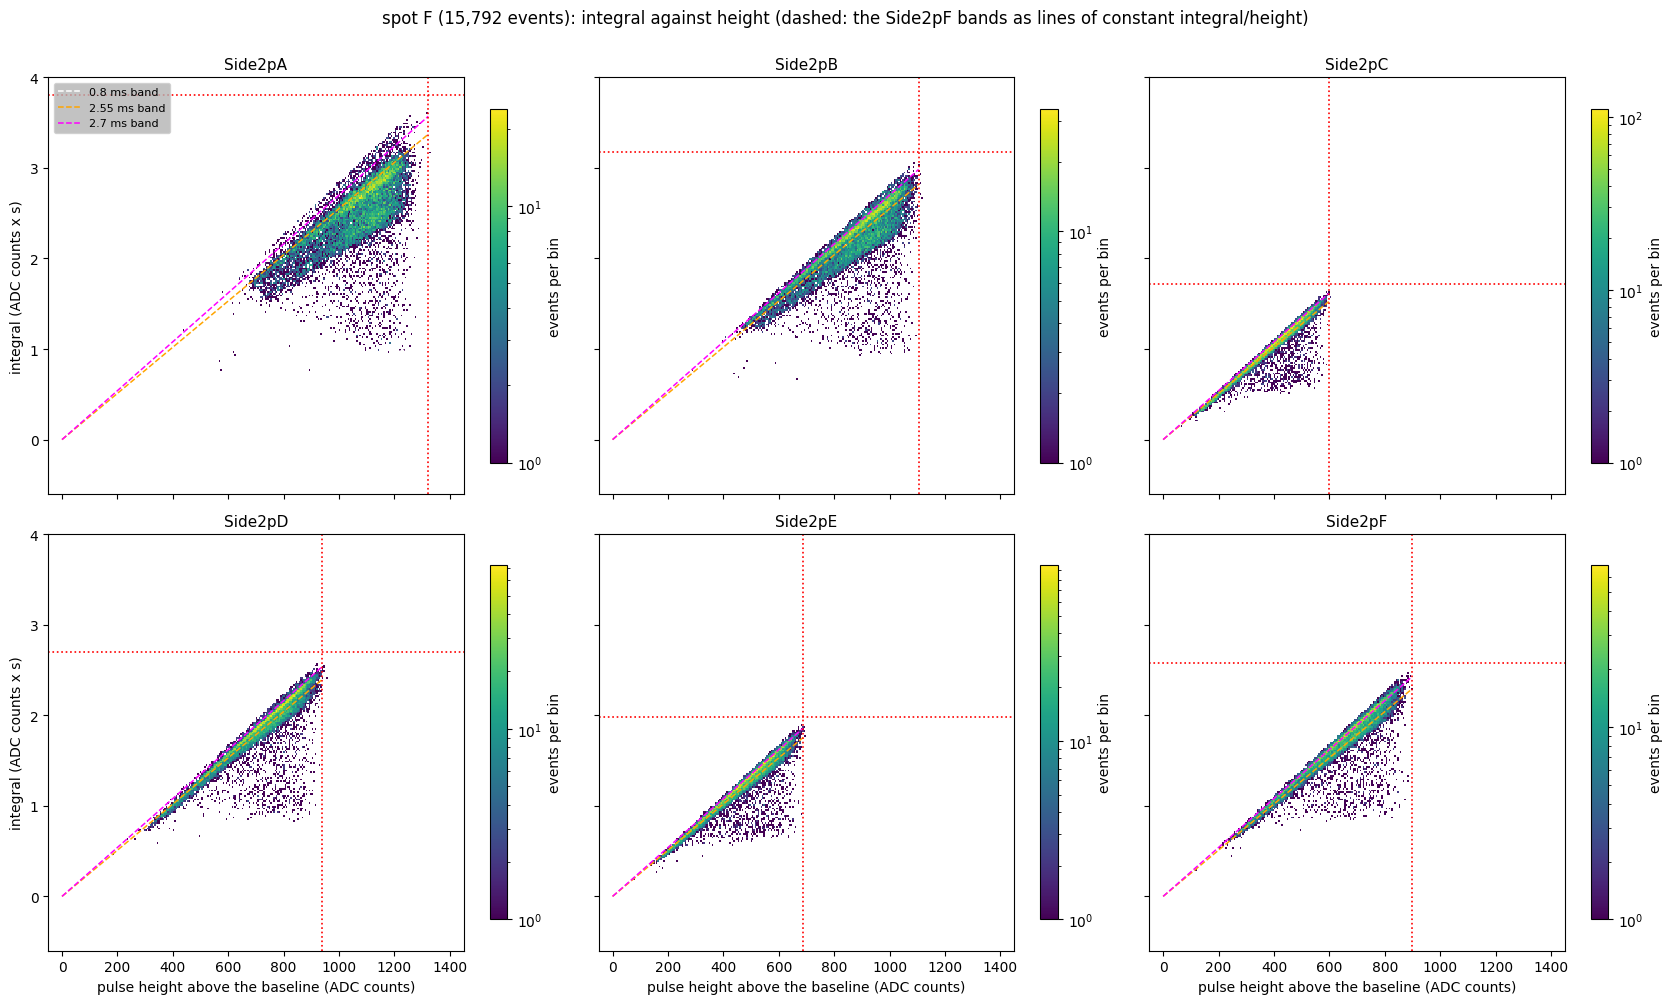

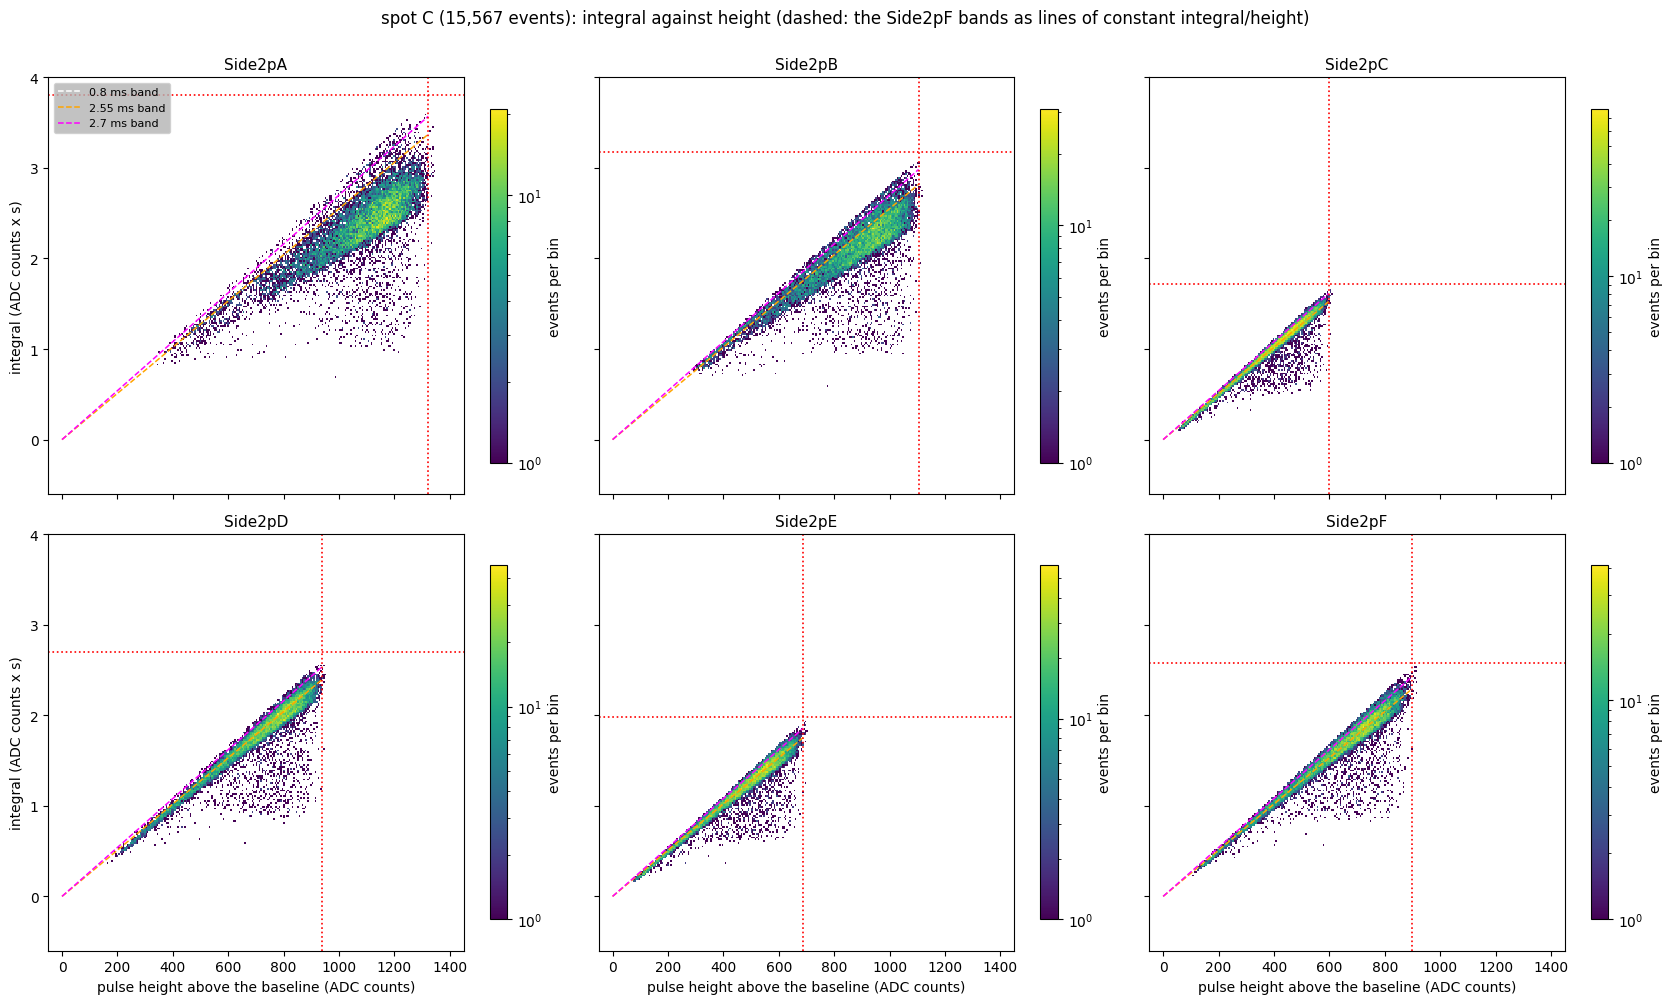

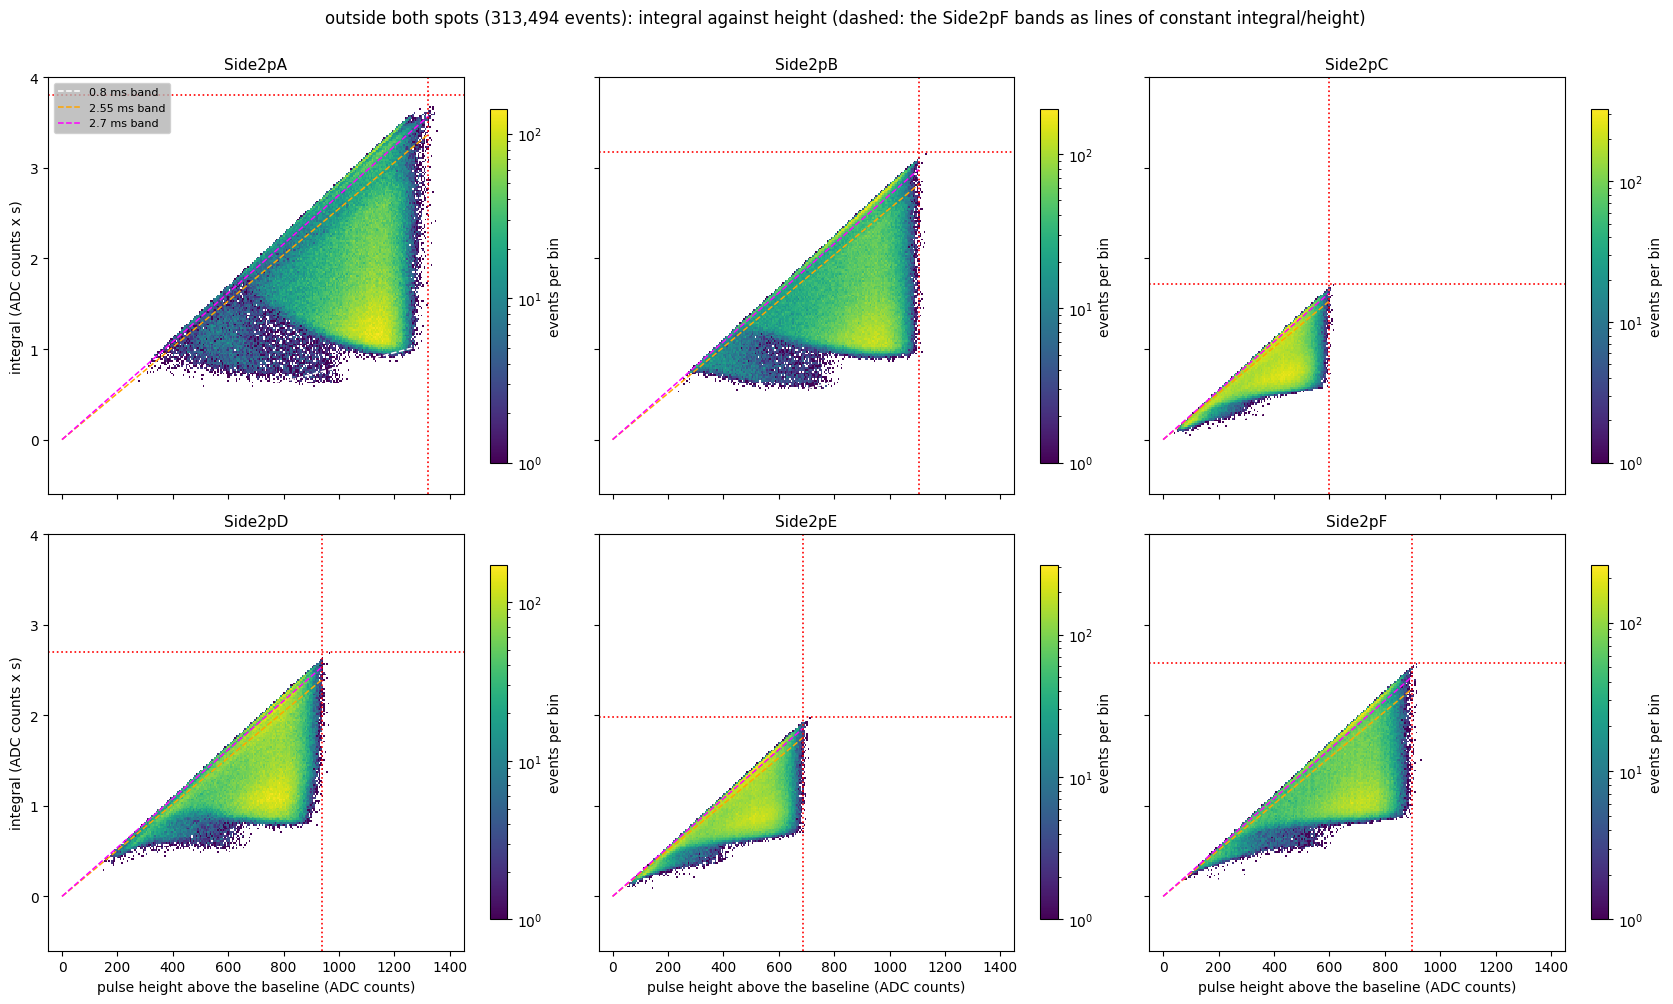

In [2]:
HR, IR = (-50, 1450), (-0.6, 4.0)
BANDS = {"0.8 ms": ("w", "--"), "2.55 ms": ("orange", "--"), "2.7 ms": ("magenta", "--")}

def band_ratio(name, k, h):
    """integral/height (ms) of the band `name` at height h; the 0.8 ms band drifts on Side2pF (integral-vs-height.ipynb)."""
    if name == "0.8 ms":
        return 0.78 + (800 - h) * 1.8e-4 if k == "F" else np.full_like(h, 0.8)
    return np.full_like(h, float(name.split()[0]))

def overlay(ax, k):
    hs = np.linspace(0, H_SAT[k], 100)
    for name, (c, ls) in BANDS.items():
        ax.plot(hs, hs * band_ratio(name, k, hs) * 1e-3, color=c, linestyle=ls, linewidth=1.1, label=f"{name} band")
    ax.axvline(H_SAT[k], color="r", linestyle=":", linewidth=1.2)
    ax.axhline(H_SAT[k] * T_AFTER, color="r", linestyle=":", linewidth=1.2)

def six_panels(m, title):
    fig, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True, sharey=True)
    for ax, k in zip(axes.flat, LETTERS):
        h = ax.hist2d(H[k][m], I[k][m], bins=[290, 230], range=[HR, IR], cmap="viridis", norm=colors.LogNorm(), cmin=1)
        overlay(ax, k)
        ax.set_xlim(*HR)
        ax.set_ylim(*IR)
        ax.set_title(f"Side2p{k}", fontsize=11)
        fig.colorbar(h[3], ax=ax, shrink=0.85, label="events per bin")
    for ax in axes[-1]:
        ax.set_xlabel("pulse height above the baseline (ADC counts)")
    for ax in axes[:, 0]:
        ax.set_ylabel("integral (ADC counts x s)")
    axes[0, 0].legend(loc="upper left", fontsize=8, facecolor="0.7")
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    plt.show()

for name, m in sel.items():
    six_panels(m, f"{name} ({m.sum():,} events): integral against height (dashed: the Side2pF bands as lines of constant integral/height)")

## Effective pulse length

`integral / height` (ms) of each channel for the three selections, each normalised to its number of events, for heights above 50 counts, with the band values marked (dashed; the 0.8 ms band of Side2pF drifts from 0.78 to 0.91 ms over its heights, shaded) and 2.88 ms, a pulse held to the end of the trace (red dotted).

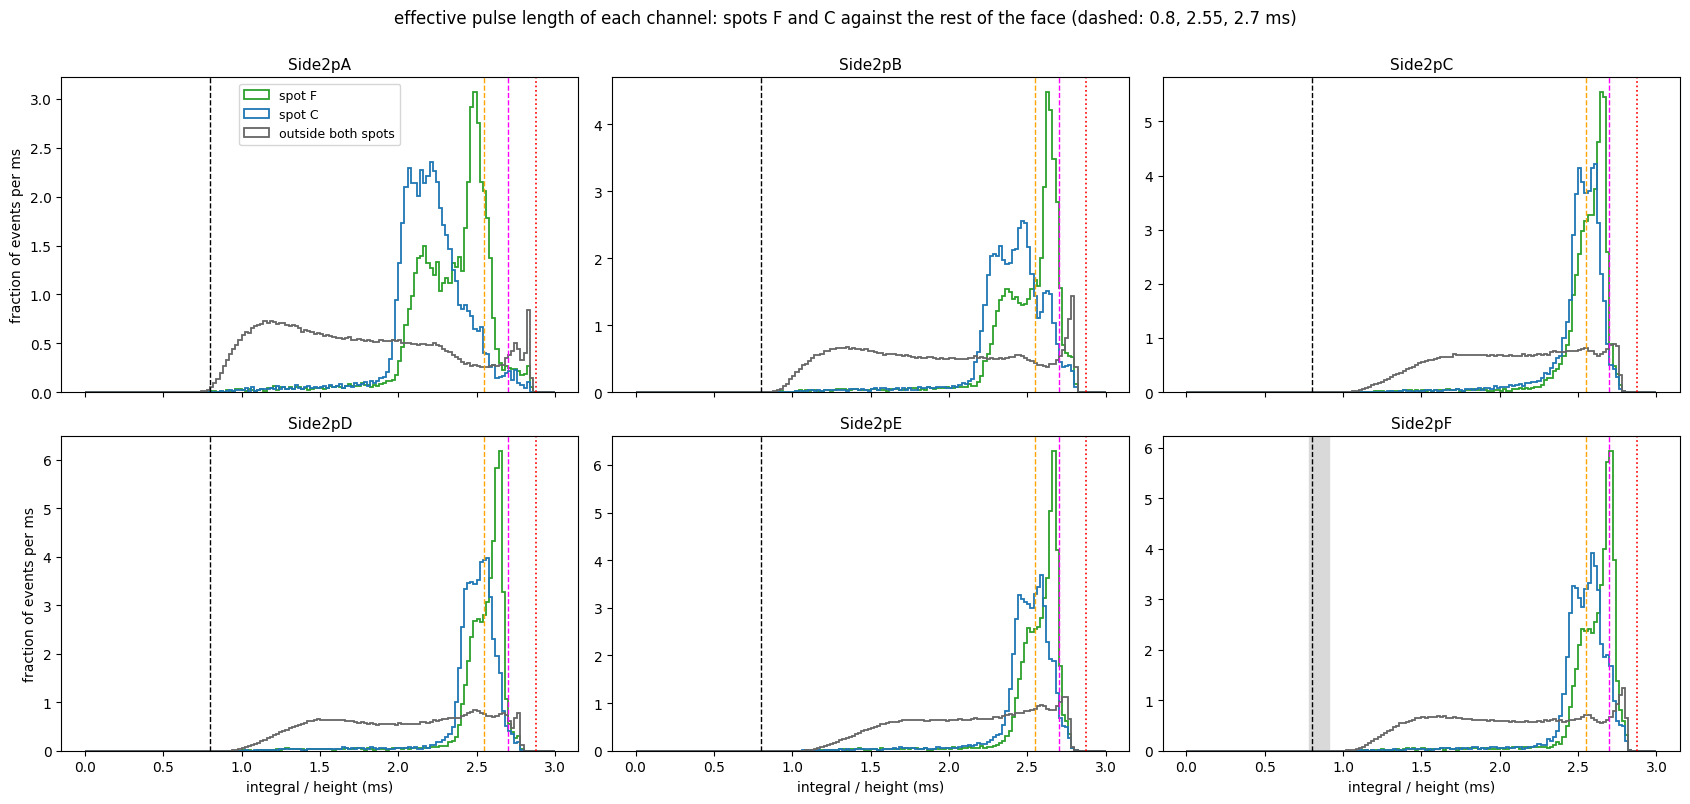

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
bins = np.linspace(0, 3, 151)
for ax, k in zip(axes.flat, LETTERS):
    for (name, m), c in zip(sel.items(), ("C2", "C0", "0.4")):
        mm = m & (H[k] > 50)
        ax.hist(I[k][mm] / H[k][mm] * 1e3, bins=bins, histtype="step", density=True, color=c, linewidth=1.3, label=name)
    if k == "F":
        ax.axvspan(0.78, 0.91, color="0.85", zorder=0)
    for name, (c, ls) in BANDS.items():
        ax.axvline(0.8 if name == "0.8 ms" else float(name.split()[0]), color="k" if c == "w" else c, linestyle=ls, linewidth=1.0)
    ax.axvline(T_AFTER * 1e3, color="r", linestyle=":", linewidth=1.2)
    ax.set_title(f"Side2p{k}", fontsize=11)
for ax in axes[-1]:
    ax.set_xlabel("integral / height (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("fraction of events per ms")
axes[0, 0].legend(fontsize=9)
fig.suptitle("effective pulse length of each channel: spots F and C against the rest of the face (dashed: 0.8, 2.55, 2.7 ms)", y=1.0)
fig.tight_layout()
plt.show()

**Not done.** The spots' own pulse shapes are in `spot-f-tight-traces.ipynb` (spot F only); this notebook only places their events in the plane of integral and height. About 5 % of each tight cut are ordinary events of that place of the face, not subtracted here.